In [1]:
import random

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cpu")

In [ ]:
from torchvision import datasets
from torchvision.transforms import v2
from torchvision.transforms import InterpolationMode

TRAIN_DATA_PATH = "./data/train/"
TEST_DATA_PATH = "./data/test/"

mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]


# transform_v1 = transforms.Compose([
#     transforms.Resize((200, 200), interpolation=InterpolationMode.BILINEAR),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=mean, std=std),
# ])

transform_v2 = v2.Compose([
    v2.Resize((200, 200), interpolation=InterpolationMode.BILINEAR),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean, std=std),
])

training_data = datasets.ImageFolder(
    root=TRAIN_DATA_PATH,
    transform=transform_v2
)

test_data = datasets.ImageFolder(
    root=TEST_DATA_PATH,
    transform=transform_v2
)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.326275].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.4482791].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7582842..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..2.5354254].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9306722..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.980906..2.5179958].
Cl

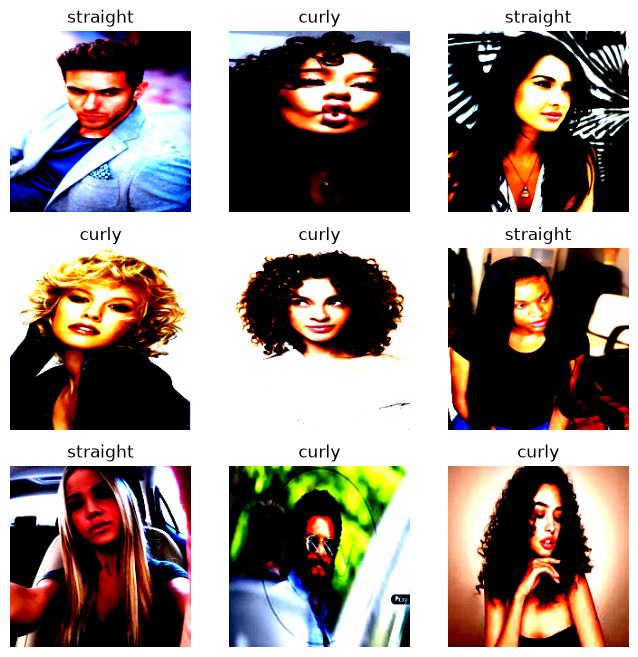

In [ ]:
import matplotlib.pyplot as plt

labels_map = {
    0: "curly",
    1: "straight",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), (1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.permute(1, 2, 0))
plt.show()


In [5]:
from torch.utils.data import DataLoader

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    training_data,
    batch_size=20,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)
evaluation_loader = DataLoader(
    test_data,
    batch_size=20,
    shuffle=False,
    num_workers=0,
)